# E-Commerce Customer Segmentation

In [1]:
# 1. Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style='whitegrid')

In [2]:
# 2. Load the data

file_path = r'/Users/farhan/Downloads/CASE-STUDY4/E-commerce_Customer_Segmentation_2026.csv'
df = pd.read_csv(file_path)

print('Rows and columns:', df.shape)
df.head()

Rows and columns: (50000, 53)


,customer_id,customer_segment,segment_category,age,age_group,gender,country,city,income_bracket,education_level,employment_type,marital_status,tenure_months,total_purchases,avg_order_value_usd,total_spent_usd,purchase_frequency,days_since_last_purchase,preferred_category_1,preferred_category_2,preferred_category_3,shopping_channel,device_used,payment_method,return_count,complaint_count,satisfaction_score,satisfaction_level,loyalty_tier,email_open_rate,click_through_rate,conversion_rate,social_media_presence,customer_lifetime_value_usd,customer_acquisition_cost_usd,customer_profitability_usd,recency_score,frequency_score,monetary_score,rfm_score,churn_risk_score,customer_health_score,dataset_year,customer_value_category,activity_status,health_status,churn_risk_category,rfm_category,profitability_category,engagement_level,behavior_segment,device_preference,clv_category
0,CUST-000001,Consumer,High Value Inactive,70,65+,Male,Canada,Winnipeg,150K+,Professional,Unemployed,Widowed,77,28,912.60,25552.80,Quarterly,63,Sports & Fitness,Home & Kitchen,NaN,In-Store,Tablet,Debit Card,15,13,5,Very Satisfied,Platinum,0.018,0.067,0.022,NaN,21281.07,96.74,21184.33,3,3,4,10,39,100,2026,High,Dormant,Excellent,Low,Potential Loyalists,High Profit,Low,Regular Buyer,Multi-Device,High CLV
1,CUST-000002,Premium,High Value Inactive,53,45-54,Female,Germany,Essen,25K-50K,High School,Student,Divorced,80,75,300.86,22564.50,Rarely,342,Automotive,Beauty,Fashion,Marketplace,Desktop,Bank Transfer,1,14,5,Very Satisfied,Gold,0.084,0.085,0.293,NaN,28347.21,199.28,28147.93,1,4,3,8,42,100,2026,Medium,Inactive,Excellent,Medium,At Risk,High Profit,Low,Occasional Buyer,Desktop-First,High CLV
2,CUST-000003,Consumer,High Value Inactive,82,65+,Male,Mexico,Puebla,75K-100K,Bachelors,Student,Married,86,163,663.91,108217.33,Quarterly,64,Fashion,Automotive,Beauty,In-Store,Tablet,Bank Transfer,1,4,3,Neutral,Diamond,0.279,0.428,0.222,NaN,103909.84,112.39,103797.45,3,5,5,13,0,100,2026,Very High,Dormant,Excellent,Very Low,Champions,High Profit,Low,Regular Buyer,Multi-Device,High CLV
3,CUST-000004,Enterprise,High Value Active,18,18-24,Male,Singapore,Singapore,150K+,Masters,Retired,Divorced,26,192,613.60,117811.20,Weekly,2,Electronics,Toys,NaN,Online,Mobile,Credit Card,11,8,5,Very Satisfied,Diamond,0.899,0.282,0.142,"Twitter, YouTube, TikTok",171318.41,140.71,171177.70,5,5,5,15,14,100,2026,Very High,Active,Excellent,Very Low,Champions,High Profit,High,Frequent Buyer,Mobile-First,High CLV
4,CUST-000005,Premium,High Value Active,64,55-64,Male,United Arab Emirates,Fujairah,150K+,PhD,Retired,Divorced,90,31,651.65,20201.15,Weekly,4,Home & Kitchen,Office Supplies,Grocery,Online,Desktop,Credit Card,7,11,1,Very Dissatisfied,Gold,0.835,0.094,0.180,"TikTok, YouTube",24465.47,52.82,24412.65,5,3,3,11,45,60,2026,Medium,Active,Fair,Medium,Loyal,High Profit,Medium,Occasional Buyer,Desktop-First,High CLV


In [3]:
# 3. Check the data

print('Unique customers:', df['customer_id'].nunique())
print('Duplicate rows:', df.duplicated().sum())
print('Missing RFM values:',
      df[['days_since_last_purchase', 'total_purchases', 'total_spent_usd']].isnull().sum().sum())

df[['days_since_last_purchase', 'total_purchases', 'total_spent_usd']].describe().round(2)

Unique customers: 50000
Duplicate rows: 0
Missing RFM values: 0


,days_since_last_purchase,total_purchases,total_spent_usd
count,50000.00,50000.00,50000.00
mean,62.97,99.42,50266.55
std,93.28,57.78,44071.21
min,0.00,0.00,0.00
25%,2.00,49.00,13893.58
50%,19.00,99.00,37541.62
75%,77.00,150.00,76811.24
max,365.00,199.00,198574.14


In [4]:
# 4. Select the RFM columns

rfm = df[['customer_id',
          'days_since_last_purchase',
          'total_purchases',
          'total_spent_usd']].copy()

rfm.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']
rfm.head()

,customer_id,Recency,Frequency,Monetary
0,CUST-000001,63,28,25552.80
1,CUST-000002,342,75,22564.50
2,CUST-000003,64,163,108217.33
3,CUST-000004,2,192,117811.20
4,CUST-000005,4,31,20201.15


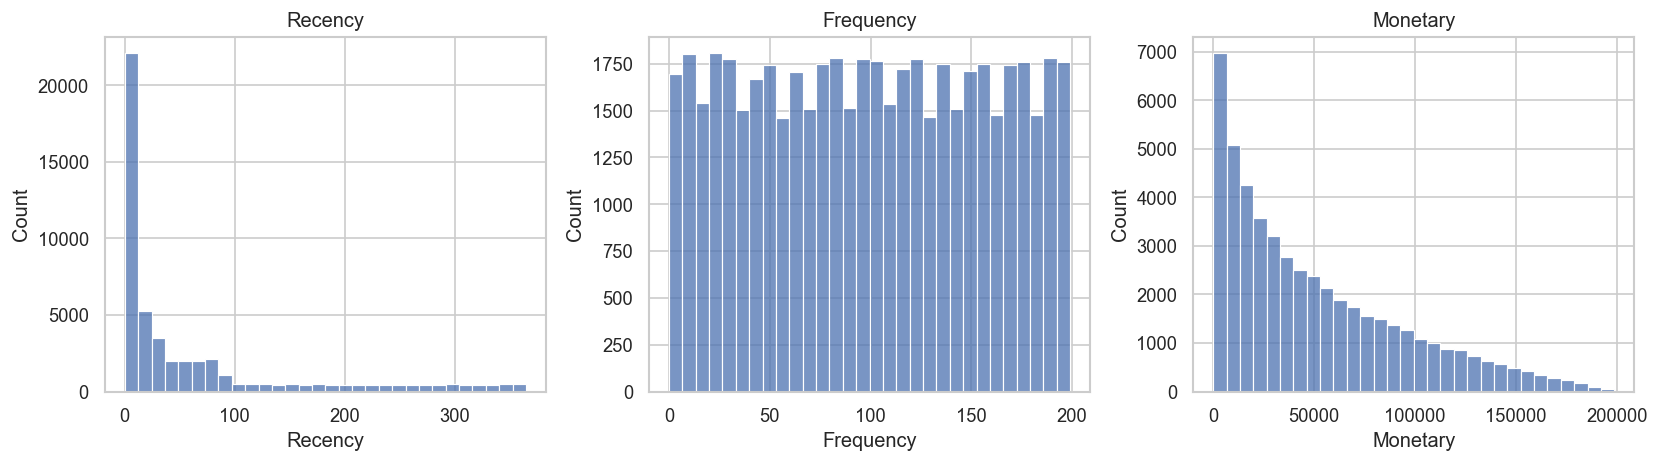

In [5]:
# 5. Look at the RFM distributions

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for column, axis in zip(['Recency', 'Frequency', 'Monetary'], axes):
    sns.histplot(rfm[column], bins=30, ax=axis)
    axis.set_title(column)

plt.tight_layout()
plt.show()

In [6]:
# 6. Log-transform and scale the RFM values

rfm_values = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_values)

print('Scaled data shape:', X_scaled.shape)

Scaled data shape: (50000, 3)


In [7]:
# 7. Compare possible K-Means cluster counts

sample_size = min(5000, len(X_scaled))
sample_index = np.random.RandomState(42).choice(
    len(X_scaled), size=sample_size, replace=False)
X_sample = X_scaled[sample_index]

k_values = list(range(1, 9))
inertia = []
silhouette_scores = []
silhouette_k = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    sample_labels = model.fit_predict(X_sample)
    inertia.append(model.inertia_)

    if k > 1:
        score = silhouette_score(
            X_sample,
            sample_labels,
            sample_size=min(2000, sample_size),
            random_state=42
        )
        silhouette_scores.append(score)
        silhouette_k.append(k)

best_k = silhouette_k[np.argmax(silhouette_scores)]
print('Best k by sampled silhouette score:', best_k)

Best k by sampled silhouette score: 2


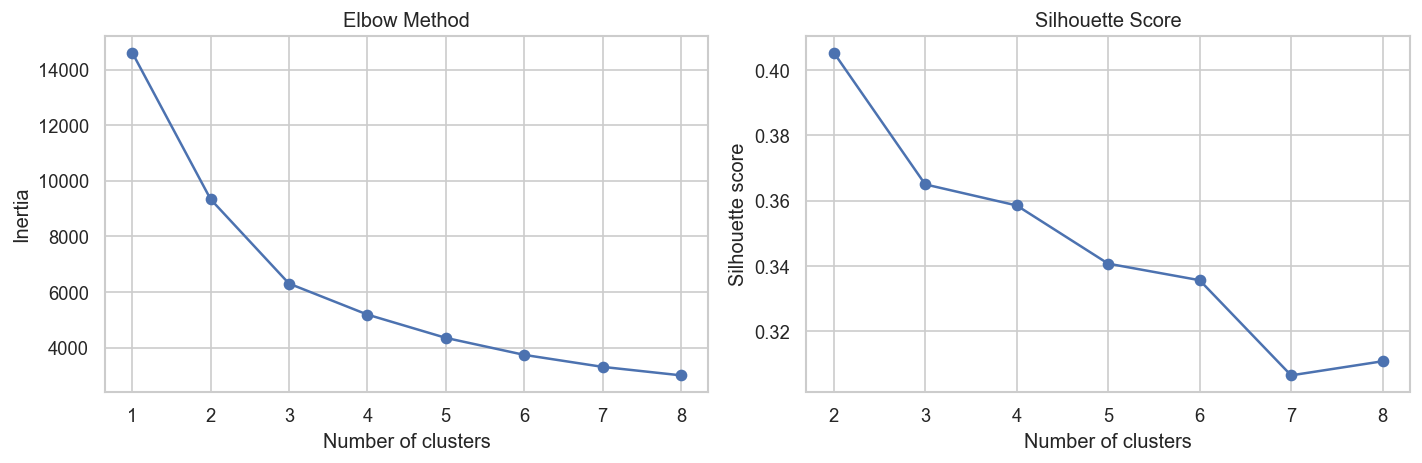

In [8]:
# 8. Plot elbow and silhouette scores

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(silhouette_k, silhouette_scores, marker='o')
plt.title('Silhouette Score')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')

plt.tight_layout()
plt.show()

In [9]:
# 9. Fit K-Means and summarize the groups

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

rfm['KMeans_Cluster'] = kmeans_labels

cluster_summary = rfm.groupby('KMeans_Cluster').agg(
    Customer_Count=('customer_id', 'count'),
    Recency_Mean=('Recency', 'mean'),
    Frequency_Mean=('Frequency', 'mean'),
    Monetary_Mean=('Monetary', 'mean')
).round(2)

cluster_summary

,Customer_Count,Recency_Mean,Frequency_Mean,Monetary_Mean
KMeans_Cluster,,,,
0,11257,62.68,25.46,7729.26
1,38743,63.05,120.91,62626.00


Variance explained by two components: 0.92


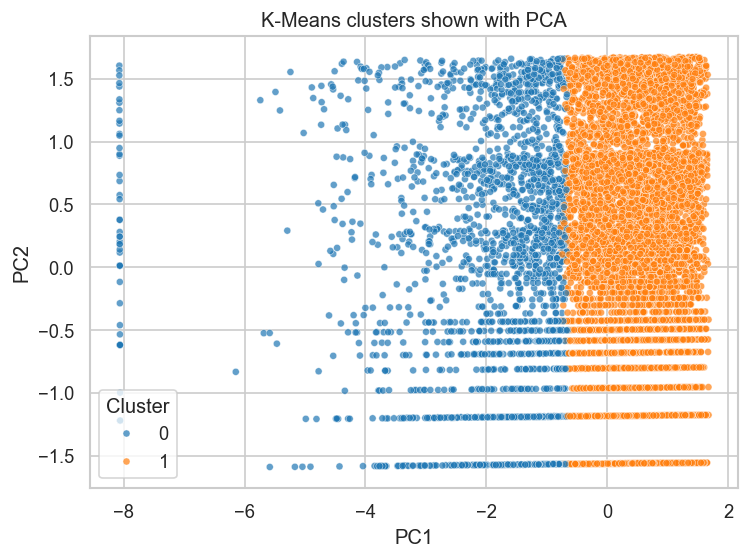

In [10]:
# 10. Use PCA to show the K-Means groups

pca = PCA(n_components=2)
pca_values = pca.fit_transform(X_scaled)

pca_data = pd.DataFrame(pca_values, columns=['PC1', 'PC2'])
pca_data['Cluster'] = kmeans_labels

print('Variance explained by two components:',
      round(pca.explained_variance_ratio_.sum(), 3))

pca_sample = pca_data.sample(n=min(10000, len(pca_data)), random_state=42)

sns.scatterplot(data=pca_sample, x='PC1', y='PC2',
                hue='Cluster', palette='tab10', s=18, alpha=0.7)
plt.title('K-Means clusters shown with PCA')
plt.tight_layout()
plt.show()

In [11]:
# 11. Use t-SNE on a sample of customers

tsne_index = np.random.RandomState(42).choice(
    len(X_scaled), size=min(2500, len(X_scaled)), replace=False)

tsne = TSNE(n_components=2, perplexity=30,
            random_state=42, init='pca', learning_rate='auto')
tsne_values = tsne.fit_transform(X_scaled[tsne_index])

tsne_data = pd.DataFrame(tsne_values, columns=['tSNE_1', 'tSNE_2'])
tsne_data['Cluster'] = kmeans_labels[tsne_index]

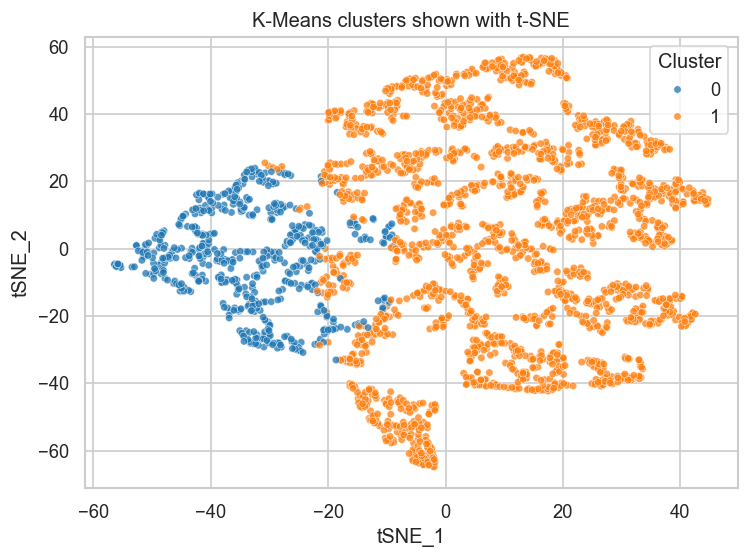

In [12]:
# 12. Plot the t-SNE view

sns.scatterplot(data=tsne_data, x='tSNE_1', y='tSNE_2',
                hue='Cluster', palette='tab10', s=20, alpha=0.75)
plt.title('K-Means clusters shown with t-SNE')
plt.tight_layout()
plt.show()

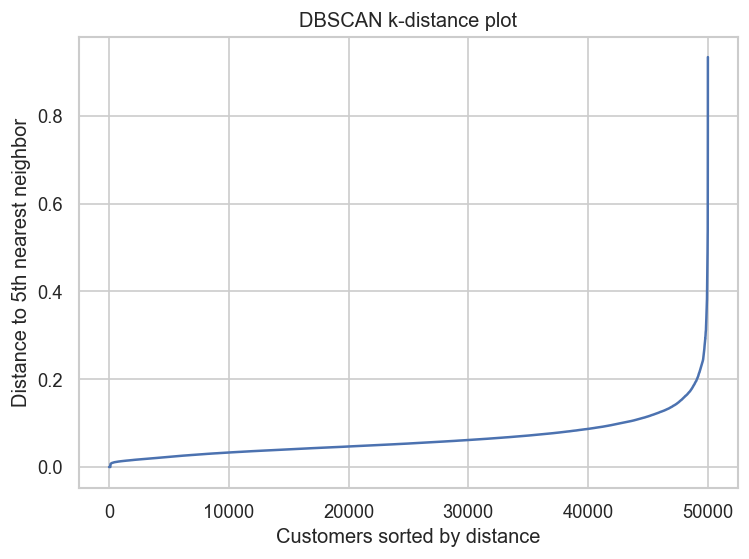

In [13]:
# 13. Use a k-distance plot to help choose DBSCAN eps

neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_scaled)
distances, indexes = neighbors.kneighbors(X_scaled)

k_distance = np.sort(distances[:, -1])

plt.plot(k_distance)
plt.title('DBSCAN k-distance plot')
plt.xlabel('Customers sorted by distance')
plt.ylabel('Distance to 5th nearest neighbor')
plt.tight_layout()
plt.show()

In [14]:
# 14. Fit DBSCAN
# Start with eps = 0.34 based on the k-distance curve; min_samples is 5.

eps_value = 0.34
min_samples = 5

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)

rfm['DBSCAN_Cluster'] = dbscan_labels

number_of_clusters = len(set(dbscan_labels) - {-1})
noise_percent = (dbscan_labels == -1).mean() * 100

print('DBSCAN clusters:', number_of_clusters)
print('Noise customers (%):', round(noise_percent, 2))
pd.Series(dbscan_labels).value_counts().sort_index()

DBSCAN clusters: 6
Noise customers (%): 0.13


-1       65
 0    44427
 1     5029
 2      199
 3      243
 4       19
 5       18
Name: count, dtype: int64

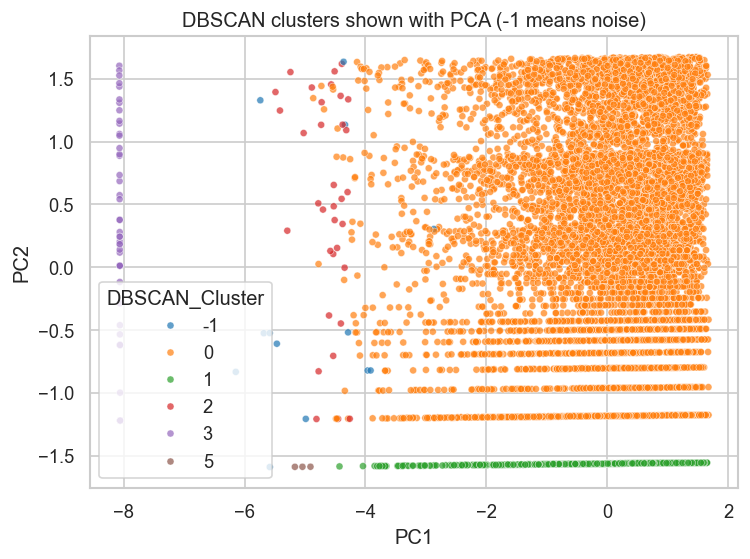

In [15]:
# 15. Show DBSCAN labels in the PCA view

pca_data['DBSCAN_Cluster'] = dbscan_labels
dbscan_sample = pca_data.sample(n=min(10000, len(pca_data)), random_state=42)

sns.scatterplot(data=dbscan_sample, x='PC1', y='PC2',
                hue='DBSCAN_Cluster', palette='tab10', s=18, alpha=0.7)
plt.title('DBSCAN clusters shown with PCA (-1 means noise)')
plt.tight_layout()
plt.show()

In [16]:
# 16. Build simple personas from the K-Means profiles

persona_profile = rfm.groupby('KMeans_Cluster').agg(
    Customer_Count=('customer_id', 'count'),
    Recency_Median=('Recency', 'median'),
    Frequency_Median=('Frequency', 'median'),
    Monetary_Median=('Monetary', 'median')
)

middle_frequency = persona_profile['Frequency_Median'].median()
middle_monetary = persona_profile['Monetary_Median'].median()

persona_names = []

for cluster in persona_profile.index:
    frequency = persona_profile.loc[cluster, 'Frequency_Median']
    monetary = persona_profile.loc[cluster, 'Monetary_Median']

    if frequency >= middle_frequency and monetary >= middle_monetary:
        persona_names.append('Champions')
    else:
        persona_names.append('Emerging Customers')

persona_profile['Persona'] = persona_names
persona_profile['Suggested_Action'] = persona_profile['Persona'].map({
    'Champions': 'Reward loyalty with VIP access, early offers, or referral rewards.',
    'Emerging Customers': 'Encourage repeat purchases with product discovery and a simple offer.'
})

persona_profile.round(2)

,Customer_Count,Recency_Median,Frequency_Median,Monetary_Median,Persona,Suggested_Action
KMeans_Cluster,,,,,,
0,11257,19.0,22.0,6034.77,Emerging Customers,Encourage repeat purchases with product discov...
1,38743,19.0,122.0,52576.26,Champions,"Reward loyalty with VIP access, early offers, ..."


In [17]:
# 17. Check popular categories and shopping channels for each persona

for cluster in persona_profile.index:
    customer_rows = df.loc[kmeans_labels == cluster]
    top_category = customer_rows['preferred_category_1'].mode().iloc[0]
    top_channel = customer_rows['shopping_channel'].mode().iloc[0]

    print('Cluster:', cluster)
    print('Persona:', persona_profile.loc[cluster, 'Persona'])
    print('Top category:', top_category)
    print('Main channel:', top_channel)
    print()

Cluster: 0
Persona: Emerging Customers
Top category: Health & Personal Care
Main channel: In-Store

Cluster: 1
Persona: Champions
Top category: Home & Kitchen
Main channel: Mobile App



In [18]:
# 18. Case study summary

print('Customers analyzed:', len(rfm))
print('K-Means clusters:', best_k)
print('DBSCAN clusters:', number_of_clusters)
print('DBSCAN noise customers (%):', round(noise_percent, 2))
print('PCA variance explained:', round(pca.explained_variance_ratio_.sum(), 3))

persona_profile

Customers analyzed: 50000
K-Means clusters: 2
DBSCAN clusters: 6
DBSCAN noise customers (%): 0.13
PCA variance explained: 0.92


,Customer_Count,Recency_Median,Frequency_Median,Monetary_Median,Persona,Suggested_Action
KMeans_Cluster,,,,,,
0,11257,19.0,22.0,6034.77,Emerging Customers,Encourage repeat purchases with product discov...
1,38743,19.0,122.0,52576.26,Champions,"Reward loyalty with VIP access, early offers, ..."
